# Fraud Decision Desk

This notebook works through one decision: how should a limited fraud-review team choose a score cutoff? The data is synthetic, and the cost inputs are assumptions rather than measured company values.

## 1. Load the project data

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(project_root / 'src'))
from analyze_fraud import ASSUMPTIONS
from analyze_fraud import build_threshold_table
from analyze_fraud import calibration_table
from analyze_fraud import decision_metrics
from analyze_fraud import score_quality
from analyze_fraud import train_scores


In [2]:
data_path = project_root / 'data' / 'synthetic_transactions.csv.gz'
transactions = pd.read_csv(data_path, parse_dates=['transaction_time'])
transactions[['transaction_time', 'amount', 'velocity_1h', 'is_fraud']].head()

,transaction_time,amount,velocity_1h,is_fraud
0,2026-01-01 00:00:00,2.83,0,0
1,2026-01-01 00:01:00,44.26,2,0
2,2026-01-01 00:03:00,52.97,0,0
3,2026-01-01 00:04:00,65.39,1,0
4,2026-01-01 00:04:00,49.61,1,0


## 2. Preserve the time order

I use the earliest records to fit the model, the next block for calibration, a later block to choose the operating threshold, and the final block only once for the test result.

In [3]:
scored, model, scaler = train_scores(transactions)
split_summary = scored.groupby('split').agg(
    rows=('transaction_id', 'count'),
    start=('transaction_time', 'min'),
    end=('transaction_time', 'max'),
    fraud_rate=('is_fraud', 'mean'),
).reset_index()
split_summary

,split,rows,start,end,fraud_rate
0,calibration,9000,2026-02-14 21:53:00,2026-02-28 05:41:00,0.006444
1,test,10800,2026-03-15 16:03:00,2026-03-31 23:55:00,0.006574
2,train_fit,30000,2026-01-01 00:00:00,2026-02-14 21:51:00,0.005800
3,validation,10200,2026-02-28 05:43:00,2026-03-15 15:59:00,0.005882


## 3. Check the score before choosing a decision

In [4]:
validation = scored[scored['split'] == 'validation'].copy()
test = scored[scored['split'] == 'test'].copy()
quality = pd.DataFrame([
    {'split': 'validation', **score_quality(validation)},
    {'split': 'test', **score_quality(test)},
])
quality

,split,average_precision,roc_auc,brier_score,fraud_rate
0,validation,0.095064,0.786764,0.005492,0.005882
1,test,0.098814,0.757928,0.006240,0.006574


In [5]:
calibration = calibration_table(test)
calibration

,score_band,transactions,average_score,observed_fraud_rate
0,"(-0.001, 0.01]",8846,0.002956,0.003278
1,"(0.01, 0.03]",1749,0.013222,0.013722
2,"(0.03, 0.06]",110,0.039940,0.009091
3,"(0.06, 0.1]",63,0.073744,0.095238
4,"(0.1, 0.2]",23,0.136988,0.304348
5,"(0.2, 0.4]",0,0.000000,0.000000
6,"(0.4, 0.7]",6,0.571407,0.333333
7,"(0.7, 1.001]",3,0.836150,0.666667


## 4. Choose the threshold on validation data

The scenario assumes 45 reviews per day, $7 for each review, $18 of customer friction for a false positive and 85% recovery of reviewed fraud value.

In [6]:
thresholds = build_threshold_table(validation, ASSUMPTIONS['daily_review_capacity'])
thresholds[['threshold', 'reviews', 'precision', 'recall', 'net_value']].head(12)

,threshold,reviews,precision,recall,net_value
0,0.15,6,0.666667,0.066667,2624.08
1,0.16,6,0.666667,0.066667,2624.08
2,0.17,6,0.666667,0.066667,2624.08
3,0.18,6,0.666667,0.066667,2624.08
4,0.19,6,0.666667,0.066667,2624.08
5,0.20,6,0.666667,0.066667,2624.08
6,0.21,6,0.666667,0.066667,2624.08
7,0.22,6,0.666667,0.066667,2624.08
8,0.23,6,0.666667,0.066667,2624.08
9,0.24,6,0.666667,0.066667,2624.08


## 5. Lock the choice and read the test result

In [7]:
selected_threshold = float(thresholds.iloc[0]['threshold'])
test_result = decision_metrics(test, selected_threshold, ASSUMPTIONS['daily_review_capacity'])
amount_baseline = test.assign(fraud_score=(test['amount'] >= test['amount'].quantile(0.95)).astype(float))
baseline_result = decision_metrics(amount_baseline, 0.5, ASSUMPTIONS['daily_review_capacity'])
pd.DataFrame([
    {'decision': 'calibrated score', **test_result},
    {'decision': 'top 5% amount baseline', **baseline_result},
])[['decision', 'reviews', 'precision', 'recall', 'net_value']]

,decision,reviews,precision,recall,net_value
0,calibrated score,9,0.444444,0.056338,3445.55
1,top 5% amount baseline,537,0.029795,0.225352,-5356.86


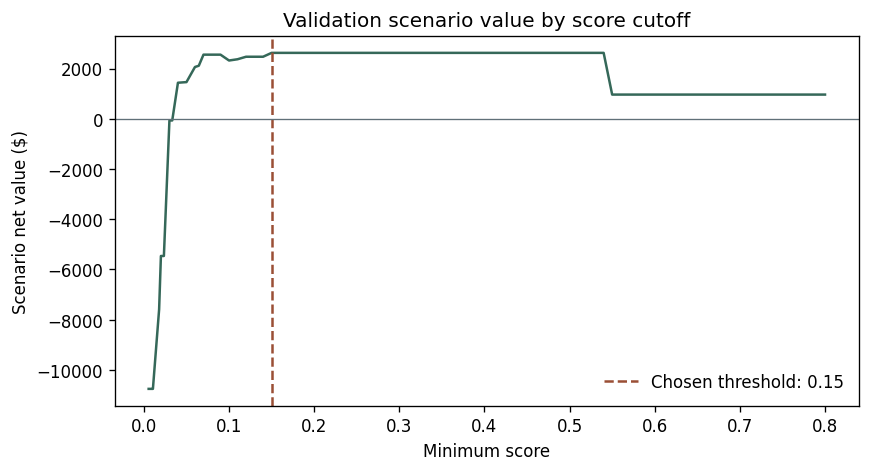

In [8]:
plot_data = thresholds.sort_values('threshold')
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(plot_data['threshold'], plot_data['net_value'], color='#356859')
ax.axvline(selected_threshold, color='#9a4f35', linestyle='--', label=f'Chosen threshold: {selected_threshold:.2f}')
ax.axhline(0, color='#607078', linewidth=0.8)
ax.set(title='Validation scenario value by score cutoff', xlabel='Minimum score', ylabel='Scenario net value ($)')
ax.legend(frameon=False)
plt.show()

## 6. Interpretation

The selected score is intentionally selective under these assumptions. On the test period it reviewed 9 of 10,800 transactions, found 4 frauds and produced 44.4% precision. Recall was only 5.6%, so this is not a claim that the model catches most fraud. It is a narrow queue choice when false positives carry a cost. Lower thresholds increase coverage, and the dashboard is meant to show that trade-off directly.